# BiasSpectr Nanonis 10 Samples

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from os.path import join

from prisma.file import load_np_val
from prisma.physics_models.jax import beem_integral_f_vector_j
from prisma.plot import plot_hist_series, plot_spectrum_series, \
    plot_spectrum_series_fit, set_rc_journal_const_wh

In [3]:
base_dir = r"C:\Users\dbasi\Documents\GitHub\PRISMA\data"
data_dir = join(base_dir, "Nanonis_Measure_ct_100_p_10_1")
figure_dir = join(base_dir, "Figure_Data")

In [4]:
set_rc_journal_const_wh()

# Samples

In [5]:
spectrum_series = load_np_val(data_dir, 'spectr_bias_series.npy')

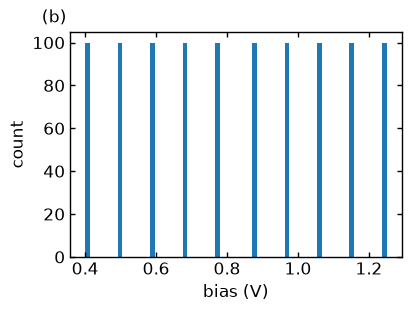

In [6]:
plot_hist_series(spectrum_series.flatten(), bins=65,
                 xlabel="bias (V)",
                #  title="Sample Locations",
                 id="(b)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_10_samples.pdf"))

# Spectrum

In [7]:
t_series = load_np_val(data_dir, 'spectr_current_series.npy')

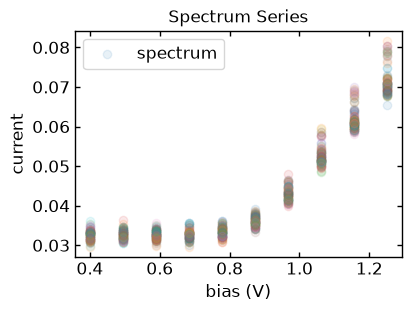

In [8]:
plot_spectrum_series(spectrum_series, -1 * t_series, xlabel="bias (V)", ylabel="current", title="Spectrum Series")

# Barrier

In [9]:
w_opt_series = load_np_val(data_dir, 'w_opt_series_Ibeem.npy')

In [10]:
barrier_fit = w_opt_series[:, 1]

In [11]:
barrier_fit

array([0.82818406, 0.84639851, 0.88811032, 0.86267511, 0.85234453,
       0.86296379, 0.85124843, 0.85872305, 0.86179213, 0.85938162,
       0.84004539, 0.85975043, 0.89254704, 0.84167796, 0.85337859,
       0.85630425, 0.82427731, 0.83535522, 0.8423382 , 0.84169406,
       0.83675183, 0.86055784, 0.85051699, 0.84207275, 0.86384826,
       0.8502437 , 0.8623618 , 0.84610372, 0.83386795, 0.88376893,
       0.85289652, 0.82011461, 0.89791998, 0.8510735 , 0.84016237,
       0.84011582, 0.85423643, 0.84153804, 0.84978203, 0.86127848,
       0.8608658 , 0.87217087, 0.86729252, 0.85874216, 0.8532701 ,
       0.84950138, 0.84847909, 0.87932328, 0.87857595, 0.84788359,
       0.89714315, 0.84964573, 0.8792974 , 0.85504108, 0.85000121,
       0.85080641, 0.85859883, 0.86178338, 0.85924895, 0.86944569,
       0.85661666, 0.84087339, 0.85759006, 0.86898197, 0.83239459,
       0.85762455, 0.85385326, 0.87943282, 0.84009594, 0.84361876,
       0.8454175 , 0.83262271, 0.87204041, 0.8856802 , 0.85491

In [12]:
np.mean(barrier_fit)

np.float64(0.8562535485402785)

In [13]:
np.std(barrier_fit)

np.float64(0.015710489161312725)

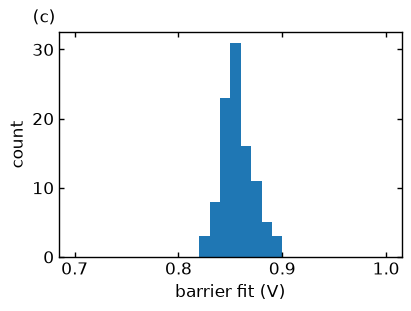

In [14]:
plot_hist_series(barrier_fit, bins=30, range=(.7, 1.),
                 xlabel="barrier fit (V)",
                #  title="Barrier Fit",
                 id="(c)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_10_barrier.pdf"))

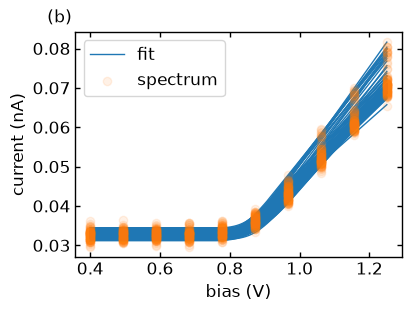

In [15]:
plot_spectrum_series_fit(spectrum_series, -1 * t_series,
                         np.linspace(np.min(spectrum_series),
                                     np.max(spectrum_series),
                                     100),
                         w_opt_series,
                         beem_integral_f_vector_j,
                         xlabel="bias (V)",
                         ylabel="current (nA)",
                         #  title="I/V Spectra",
                         f_save=join(figure_dir, "BiasSpectr_nanonis_10_spectrum_fit.pdf"),
                         id="(b)",
                         color_fit='C0', color_series='C1')

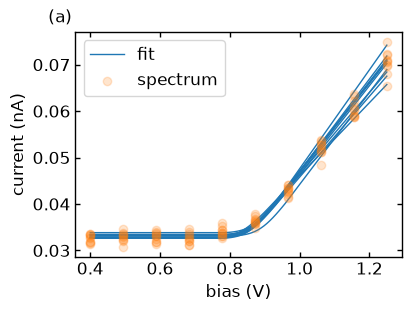

In [16]:
subset_lim = 10
plot_spectrum_series_fit(spectrum_series[:subset_lim], -1 * t_series[:subset_lim],
                         np.linspace(np.min(spectrum_series),
                                     np.max(spectrum_series),
                                     100),
                         w_opt_series[:subset_lim],
                         beem_integral_f_vector_j,
                         xlabel="bias (V)",
                         ylabel="current (nA)",
                         #  title="I/V Spectra",
                         f_save=join(figure_dir, "BiasSpectr_nanonis_10_spectrum_fit_subset.pdf"),
                         id="(a)",
                         color_fit='C0', color_series='C1', alpha=.2)

# Confidence

In [17]:
w_cov_series = load_np_val(data_dir, 'w_cov_Ibeem_series_Ibeem.npy')

In [18]:
barrier_stddev = np.sqrt(w_cov_series[:, 1, 1])

In [19]:
barrier_stddev

array([0.0176491 , 0.01984504, 0.01562415, 0.01580237, 0.0130801 ,
       0.01298025, 0.01228483, 0.01154534, 0.01661017, 0.01041385,
       0.01793722, 0.01187302, 0.01331373, 0.00858828, 0.00660076,
       0.01275562, 0.01258863, 0.00916145, 0.00994301, 0.01475384,
       0.01483739, 0.0132582 , 0.01383956, 0.00944264, 0.01028074,
       0.00849066, 0.01075968, 0.01068606, 0.01225052, 0.01424193,
       0.0155729 , 0.01366277, 0.01992315, 0.01299735, 0.01057513,
       0.01429231, 0.01351073, 0.01973272, 0.00789676, 0.01465856,
       0.00955687, 0.006644  , 0.01495079, 0.01045471, 0.01261626,
       0.00888396, 0.01156614, 0.01155135, 0.01205699, 0.0109625 ,
       0.00881432, 0.01136867, 0.01225108, 0.01649425, 0.03126434,
       0.01275469, 0.0101943 , 0.01115395, 0.01401188, 0.00842113,
       0.00944191, 0.01571995, 0.01147852, 0.0087745 , 0.01753328,
       0.01227086, 0.01472245, 0.01543783, 0.01757249, 0.01045864,
       0.01449786, 0.01310903, 0.00901747, 0.01201918, 0.01180

In [20]:
np.mean(barrier_stddev)

np.float64(0.013004339314776259)

In [21]:
np.std(barrier_stddev)

np.float64(0.0036187330271958695)

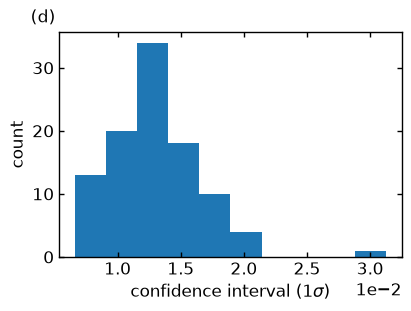

In [22]:
plot_hist_series(barrier_stddev, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                #  title="Barrier Confidence",
                 id="(d)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_10_barrier_stddev.pdf"))

# Threshold

In [23]:
w_opt_series[:, 2]

array([7.84215449e-06, 8.81334074e-06, 9.89954774e-06, 8.69778340e-06,
       9.43832074e-06, 9.92635088e-06, 9.64713497e-06, 9.55192976e-06,
       9.64420402e-06, 1.06449366e-05, 9.99436811e-06, 1.24615159e-05,
       1.22789291e-05, 1.14289157e-05, 1.16386123e-05, 1.06749970e-05,
       9.11400074e-06, 9.55019354e-06, 9.50309752e-06, 9.40517018e-06,
       9.59917002e-06, 1.13328833e-05, 1.09706626e-05, 1.07474537e-05,
       1.16474529e-05, 1.12052645e-05, 1.18675146e-05, 1.16642739e-05,
       1.09659077e-05, 9.84290631e-06, 9.26150739e-06, 8.52512927e-06,
       1.18562519e-05, 8.96295666e-06, 9.22867836e-06, 9.32693406e-06,
       9.56343298e-06, 8.93575576e-06, 9.57686245e-06, 9.62041383e-06,
       9.25066174e-06, 9.53561596e-06, 9.51220473e-06, 9.83469168e-06,
       8.94664013e-06, 9.31629448e-06, 9.29786299e-06, 9.70554355e-06,
       1.00402128e-05, 9.33649759e-06, 1.01577236e-05, 9.17359721e-06,
       9.99953971e-06, 9.62819555e-06, 1.02607185e-05, 9.71911639e-06,
      

In [24]:
# thresh_series = w_opt_series[:, 2] < 1.4e-5
thresh_series = (w_opt_series[:, 1] > .8) & (w_opt_series[:, 1] < .89)

In [25]:
np.sum(thresh_series)

np.int64(97)

In [26]:
spectrum_series_thresh = spectrum_series[thresh_series]

In [27]:
t_series_thresh = t_series[thresh_series]

# Spectrum

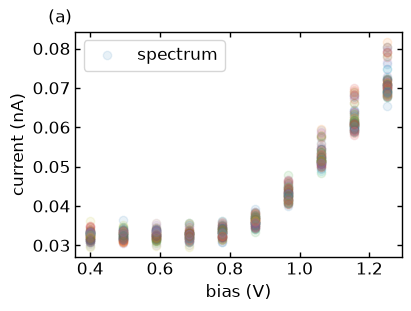

In [28]:
plot_spectrum_series(spectrum_series_thresh, -1 * t_series_thresh,
                     xlabel="bias (V)",
                     ylabel="current (nA)",
                    #  title="I/V Spectra",
                     f_save=join(figure_dir, "BiasSpectr_nanonis_10_spectrum_rmout.pdf"),
                     id="(a)")

# Samples

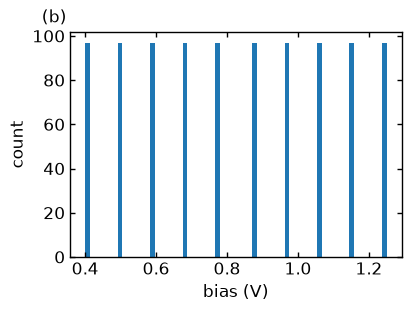

In [29]:
plot_hist_series(spectrum_series_thresh.flatten(), bins=65,
                 xlabel="bias (V)",
                #  title="Sample Locations",
                 id="(b)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_10_samples_rmout.pdf"))

# Barrier

In [30]:
w_opt_series_thresh = w_opt_series[thresh_series]

In [31]:
barrier_fit_thresh = w_opt_series_thresh[:, 1]

In [32]:
np.mean(barrier_fit_thresh)

np.float64(0.8550282957321871)

In [33]:
np.std(barrier_fit_thresh)

np.float64(0.0142911759580757)

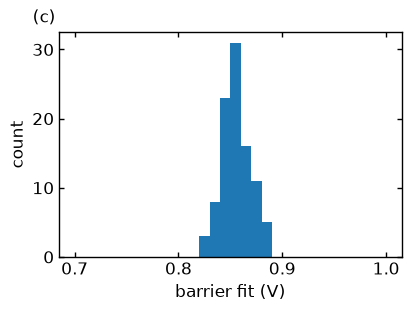

In [34]:
plot_hist_series(barrier_fit_thresh, bins=30, range=(.7, 1.),
                 xlabel="barrier fit (V)",
                #  title="Barrier Fit",
                 id="(c)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_10_barrier_rmout.pdf"))

# Spectrum Fit

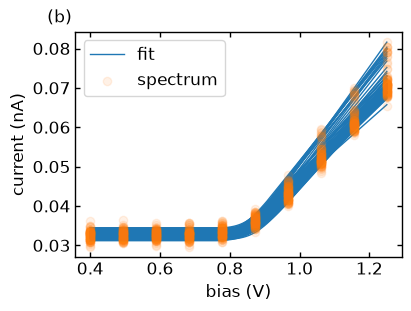

In [35]:
plot_spectrum_series_fit(spectrum_series_thresh, -1 * t_series_thresh,
                         np.linspace(np.min(spectrum_series_thresh),
                                     np.max(spectrum_series_thresh),
                                     100),
                         w_opt_series_thresh,
                         beem_integral_f_vector_j,
                         xlabel="bias (V)",
                         ylabel="current (nA)",
                         #  title="I/V Spectra",
                         f_save=join(figure_dir, "BiasSpectr_nanonis_10_spectrum_fit_rmout.pdf"),
                         id="(b)",
                         color_fit='C0', color_series='C1')

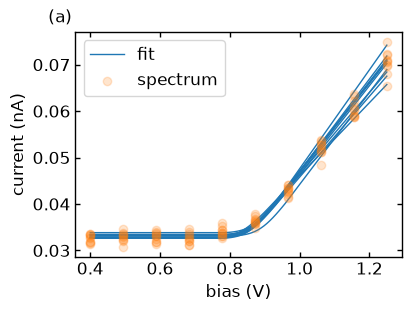

In [36]:
subset_lim = 10
plot_spectrum_series_fit(spectrum_series_thresh[:subset_lim], -1 * t_series_thresh[:subset_lim],
                         np.linspace(np.min(spectrum_series_thresh),
                                     np.max(spectrum_series_thresh),
                                     100),
                         w_opt_series_thresh[:subset_lim],
                         beem_integral_f_vector_j,
                         xlabel="bias (V)",
                         ylabel="current (nA)",
                         #  title="I/V Spectra",
                         f_save=join(figure_dir, "BiasSpectr_nanonis_10_spectrum_fit_rmout_subset.pdf"),
                         id="(a)",
                         color_fit='C0', color_series='C1', alpha=.2)

# Confidence

In [37]:
w_cov_series_thresh = w_cov_series[thresh_series]

In [38]:
barrier_stddev_thresh = np.sqrt(w_cov_series_thresh[:, 1, 1])

In [39]:
np.mean(barrier_stddev_thresh)

np.float64(0.01297301777580182)

In [40]:
np.std(barrier_stddev_thresh)

np.float64(0.003581029385579635)

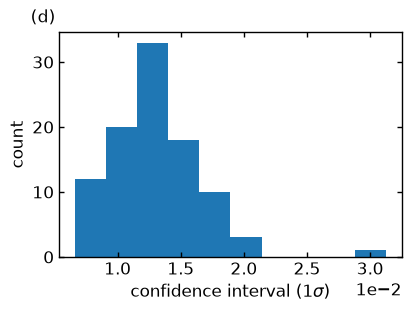

In [41]:
plot_hist_series(barrier_stddev_thresh, bins=10,
                 x_label_scinot=True,
                 xlabel=r"confidence interval ($1 \sigma$)",
                #  title="Barrier Confidence",
                 id="(d)",
                 f_save=join(figure_dir, "BiasSpectr_nanonis_10_barrier_stddev_rmout.pdf"))